# TP1 — Prédire un nombre : la régression avec un réseau de neurones
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- La différence entre **régression** (prédire un nombre) et classification (prédire une catégorie)
- Pourquoi la dernière couche n'a **pas** d'activation, et pourquoi on utilise la perte **MSE**
- Lire **MAE, RMSE et R²** et savoir ce qu'ils disent
- Reconnaître le **sous-apprentissage** (réseau trop petit) et le surapprentissage (trop peu de données)
- Constater qu'**un réseau n'est pas toujours meilleur** qu'une méthode simple

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`np.random.default_rng`  ·  `plt.scatter`  ·  `train_test_split`  ·  `LinearRegression`  ·  `r2_score`  ·  `mean_absolute_error`  ·  `keras.Sequential`  ·  `layers.Dense`  ·  `model.compile`  ·  `model.fit`  ·  `model.predict`  ·  `StandardScaler`  ·  `load_diabetes`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Les données : une courbe et du bruit
En **régression**, on prédit un **nombre** (ici la hauteur `y` d'une courbe à partir de sa position `x`). Nous fabriquons les données nous-mêmes : un sinus, plus un peu de bruit aléatoire. Une **droite** ne pourra pas suivre cette courbe, un **réseau** si.

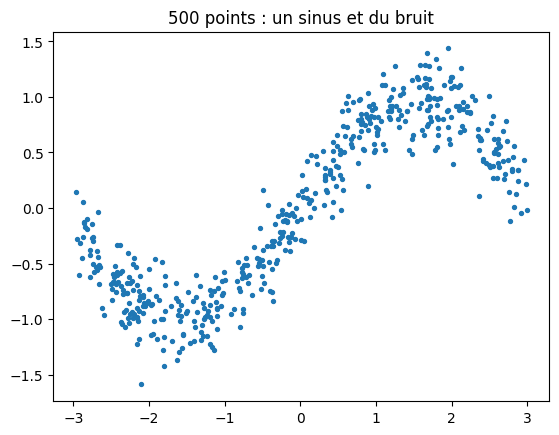

In [2]:
rng = np.random.default_rng(42)
x = rng.uniform(-3, 3, 500)
y = np.sin(x) + rng.normal(0, 0.2, 500)
plt.scatter(x, y, s=8); plt.title("500 points : un sinus et du bruit"); plt.show()

## 🎯 Étape 2 — Découper en apprentissage et test
On garde **20 % des points de côté** : le réseau ne les verra jamais pendant l'apprentissage. Ils serviront de verdict final. Keras attend des entrées **à 2 dimensions** : `x` doit devenir un tableau de forme `(500, 1)`.

**À faire :** Faites `X` (500 lignes, 1 colonne) à partir de `x`, puis découpez en `x_train`, `x_test`, `y_train`, `y_test` : **20 % de test**, `random_state=42`.

> 💡 **Indice** : `reshape(-1, 1)` met un vecteur en colonne. `train_test_split` renvoie 4 morceaux dans un ordre précis : lisez sa documentation.

In [3]:
X = x.reshape(-1, 1)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [4]:
# ✅ Contrôle (ne pas modifier)
controle(x_train.shape == (400, 1) and x_test.shape == (100, 1), 'Découpage correct : 400 / 100', 'Attendu (400, 1) et (100, 1)')

✅ Découpage correct : 400 / 100


## 🎯 Étape 3 — La référence : une droite
Avant tout réseau, on regarde ce que fait **la méthode la plus simple** : une droite. Le **R²** mesure la part de variation expliquée : **1 = parfait, 0 = pas mieux que prédire toujours la moyenne**.

**À faire :** Entraînez une régression linéaire sur `x_train`, puis calculez son **R² sur le test** dans une variable `r2_lineaire`.

> 💡 **Indice** : `LinearRegression`, ses méthodes `fit` et `predict`, puis `r2_score(vrais, prédits)`.

In [5]:
from sklearn.linear_model import LinearRegression
# TODO : calculer r2_lineaire
modele_linear = LinearRegression()
modele_linear.fit(x_train, y_train)
y_pred_lin = modele_linear.predict(x_test)
r2_lineaire = r2_score(y_test, y_pred_lin)

In [6]:
# ✅ Contrôle (ne pas modifier)
controle(0.5 < r2_lineaire < 0.8, 'R² de la droite plausible', 'Attendu un R² entre 0.5 et 0.8 : une droite explique une partie seulement de la courbe')

✅ R² de la droite plausible


## 🎯 Étape 4 — Construire le réseau
Un réseau de régression ressemble à celui d'une classification, avec **deux différences** : la **dernière couche n'a pas d'activation** (elle doit pouvoir sortir n'importe quel nombre, pas seulement entre 0 et 1), et la **perte** est la **MSE** (erreur quadratique moyenne : la moyenne des carrés des écarts).

**À faire :** Construisez `modele` : entrée de taille 1, **deux couches cachées de 32 neurones (ReLU)**, **une sortie de 1 neurone sans activation**. Compilez avec l'optimiseur **adam**, la perte **mse** et la métrique **mae**. Affichez le résumé.

> 💡 **Indice** : `keras.Sequential([...])`, `layers.Input`, `layers.Dense`, `model.compile`, `model.summary`.

In [7]:
keras.utils.set_random_seed(42)
# TODO : construire et compiler modele
modele = keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(32, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

modele.compile(optimizer='adam', loss='mse', metrics=['mae'])
modele.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# ✅ Contrôle (ne pas modifier)
controle(modele.count_params() == 1153, 'Réseau correct : 1 153 paramètres', 'Attendu 1 153 paramètres, obtenu ' + str(modele.count_params()) + ' : vérifiez les couches')

✅ Réseau correct : 1 153 paramètres


## 🎯 Étape 5 — Entraîner
Un **epoch** est un passage complet sur les données d'apprentissage. On met aussi **20 % de l'apprentissage de côté** (`validation_split`) : à chaque epoch, on mesure l'erreur sur ces points que le réseau n'utilise pas pour se corriger.

**À faire :** Entraînez `modele` : **200 epochs**, **batch de 32**, **20 % de validation**, sans affichage. Stockez le résultat dans `histoire`.

> 💡 **Indice** : `model.fit(...)` renvoie un objet « historique ». Cherchez les arguments `epochs`, `batch_size`, `validation_split`, `verbose`.

In [9]:
# TODO : entraîner modele et stocker le résultat dans histoire
histoire = modele.fit(x_train, y_train, epochs=200, batch_size=32, validation_split=0.2, verbose=0)


In [10]:
# ✅ Contrôle (ne pas modifier)
controle(len(histoire.history['loss']) == 200, '200 epochs effectués', 'Attendu 200 epochs')

✅ 200 epochs effectués


## Étape 6 — Lire la courbe de perte
La perte (MSE) doit **baisser puis se stabiliser**. La courbe orange (validation) est notre détecteur de triche.

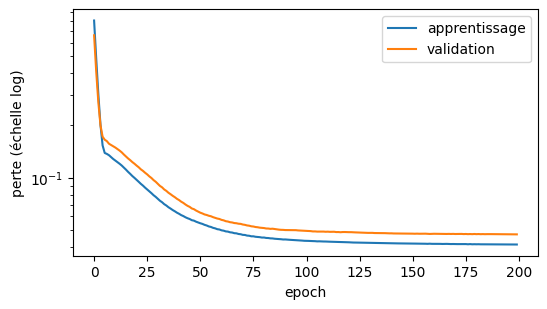

In [11]:
plt.figure(figsize=(6, 3.2))
plt.plot(histoire.history["loss"], label="apprentissage"); plt.plot(histoire.history["val_loss"], label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("perte (échelle log)"); plt.legend(); plt.show()

### ✍️ Question
**À partir de quel epoch environ la courbe devient-elle plate ? Les 200 epochs étaient-ils nécessaires ?**

La courbe devient généralement plate autour de 50 à 100 epochs. Les 200 epochs n'étaient pas tous nécessaires car l'erreur de validation (courbe orange) cesse de diminuer bien avant la fin, indiquant que le modèle n'apprend plus rien d'utile.

>

## 🎯 Étape 7 — Évaluer : trois mesures de l'erreur
Sur le test, trois chiffres complémentaires :
- **MAE** : l'erreur moyenne, dans l'unité de `y` (facile à expliquer à un non-spécialiste) ;
- **RMSE** : comme la MAE, mais les **grosses erreurs pèsent plus** ;
- **R²** : de 0 à 1, la part de variation expliquée.

**À faire :** Prédisez `y_pred` sur `x_test` (tableau à une dimension), puis calculez `r2_reseau`, `mae` et `rmse`. Le RMSE est la racine de la moyenne des carrés des écarts.

> 💡 **Indice** : `model.predict(...)` renvoie un tableau à 2 dimensions : `.ravel()` le met à plat. `mean_absolute_error`, `r2_score`, `np.sqrt`, `np.mean`.

In [12]:
# TODO : calculer y_pred, r2_reseau, mae, rmse
y_pred = modele.predict(x_test).ravel()

r2_reseau = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(np.mean((y_test - y_pred)**2))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


In [13]:
# ✅ Contrôle (ne pas modifier)
controle(r2_reseau > 0.85 and r2_reseau > r2_lineaire, 'Le réseau bat la droite', 'Attendu un R² du réseau supérieur à 0.85 et à celui de la droite')

✅ Le réseau bat la droite


## Étape 8 — Voir ce que le réseau a appris
On trace la courbe prédite par le réseau (rouge) contre la vraie courbe (gris pointillé). C'est la meilleure façon de **comprendre** ce qu'un modèle a fait.

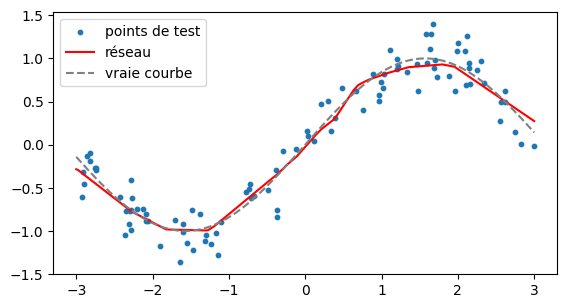

In [14]:
xs = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.figure(figsize=(6.5, 3.4))
plt.scatter(x_test, y_test, s=10, label="points de test")
plt.plot(xs, modele.predict(xs, verbose=0), color="red", label="réseau")
plt.plot(xs, np.sin(xs), "--", color="gray", label="vraie courbe")
plt.legend(); plt.show()

## 🎯 Étape 9 — Expérience : combien de neurones faut-il ?
Un réseau trop petit ne peut pas suivre la courbe : c'est le **sous-apprentissage**. Mesurons-le.

**À faire :** Pour des réseaux à **une seule couche cachée** de **1, 4, 32 puis 256 neurones** (200 epochs, batch 32, sans validation), calculez le **R² sur le test**. Rangez les résultats dans un dictionnaire `resultats` (clé = nombre de neurones). Tracez les 4 courbes prédites côte à côte.

> 💡 **Indice** : Une boucle `for n in (1, 4, 32, 256)`. Pensez à refixer la graine (`set_random_seed`) à chaque tour pour comparer à armes égales.

In [16]:
import keras.backend as K

resultats = {}
# TODO : boucle sur 1, 4, 32, 256 neurones
for n in [1, 4, 32, 256]:
    K.clear_session()
    keras.utils.set_random_seed(42)
    modele_test = keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(n, activation='relu'),
        layers.Dense(1)
    ])
    modele_test.compile(optimizer='adam', loss='mse')
    modele_test.fit(x_train, y_train, epochs=200, batch_size=32, verbose=0)

    preds = modele_test.predict(x_test, verbose=0).ravel()
    resultats[n] = r2_score(y_test, preds)


In [17]:
# ✅ Contrôle (ne pas modifier)
controle(len(resultats) == 4 and resultats[1] < resultats[32], 'Un seul neurone fait moins bien que 32', 'Attendu 4 résultats, avec R² de 1 neurone < R² de 32 neurones')

✅ Un seul neurone fait moins bien que 32


### ✍️ Question
**Que se passe-t-il avec un seul neurone ? Passer de 32 à 256 neurones change-t-il beaucoup le résultat ?**

Avec un seul neurone, le modèle manque de complexité et sous-apprend la courbe. Passer de 32 à 256 neurones modifie très peu le résultat, ce qui prouve que 32 neurones offrent déjà la flexibilité requise pour modéliser cette fonction sinus.

>

## 🎯 Étape 10 — Expérience : trop peu de données
Cette fois c'est l'inverse : un **gros** réseau (2 couches de 256 neurones) mais **très peu de données**. Il peut alors mémoriser chaque point, bruit compris : c'est le **surapprentissage**.

**À faire :** N'utilisez que les **15 premiers points** de `x_train` / `y_train`. Entraînez le gros réseau **500 epochs** (batch 8). Calculez `r2_train` (sur ces 15 points) et `r2_test` (sur tout le test). Tracez la courbe prédite.

> 💡 **Indice** : Découpez avec `x_train[:15]`. Comparez les deux R² : que valent-ils chacun ?

In [18]:
# TODO : calculer r2_train et r2_test avec seulement 15 points
x_train_petit = x_train[:15]
y_train_petit = y_train[:15]

gros_modele = keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(256, activation='relu'),
    layers.Dense(256, activation='relu'),
    layers.Dense(1)
])
gros_modele.compile(optimizer='adam', loss='mse')
gros_modele.fit(x_train_petit, y_train_petit, epochs=500, batch_size=8, verbose=0)

r2_train = r2_score(y_train_petit, gros_modele.predict(x_train_petit).ravel())
r2_test = r2_score(y_test, gros_modele.predict(x_test).ravel())


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


In [19]:
# ✅ Contrôle (ne pas modifier)
controle(r2_train > r2_test, 'R² d\'apprentissage supérieur au R² de test : signe de surapprentissage', 'Attendu r2_train > r2_test')

✅ R² d'apprentissage supérieur au R² de test : signe de surapprentissage


### ✍️ Question
**Comparez R² d'apprentissage et R² de test. Que vous dit l'écart ? Que faudrait-il pour le réduire ?**  

Le R² d'apprentissage est nettement supérieur au R² de test. Cet écart très important confirme que le modèle fait du surapprentissage. Parce que le réseau est très complexe (deux couches de 256 neurones) et qu'il n'a vu que 15 points, il a fini par les apprendre par cœur avec leurs défauts, le rendant incapable de faire de bonnes prédictions sur de nouvelles données.  
   Pour réduire cet écart, il faut soit lui donner beaucoup plus de données pour s'entraîner, soit réduire la taille du réseau (moins de neurones ou de couches) pour l'empêcher de mémoriser.


>

## 🎯 Étape 11 — Sur des données réelles : la progression du diabète
Reprenez **toute la démarche** sur un vrai jeu : `load_diabetes` (442 patients, 10 mesures médicales, cible = indice de progression de la maladie). Ici les 10 colonnes ont des échelles différentes : il faut les **mettre à l'échelle**, en calculant la moyenne et l'écart-type **sur l'apprentissage seul**.

**À faire :** 1) Découpez (20 % de test, `random_state=42`) vers `Xd_train`, `Xd_test`, `yd_train`, `yd_test`. 2) Standardisez (fit sur train, transform sur train et test). 3) Régression linéaire → `r2_lin_d`. 4) Réseau **16 puis 8 neurones**, 150 epochs max, batch 16, validation 20 %, **arrêt précoce** (patience 15, `restore_best_weights=True`) → `r2_res_d`.

> 💡 **Indice** : `StandardScaler` : `fit` puis `transform`. `keras.callbacks.EarlyStopping`. Pour un réseau de régression, rappelez-vous la sortie et la perte.

In [20]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from keras.callbacks import EarlyStopping

# TODO : tout le pipeline sur le jeu du diabète
# Découpage
X_diab, y_diab = load_diabetes(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_diab, y_diab, test_size=0.2, random_state=42)

# Standardisation
scaler = StandardScaler()
Xd_train_scaled = scaler.fit_transform(Xd_train)
Xd_test_scaled = scaler.transform(Xd_test)

# Régression linéaire
lin_d = LinearRegression()
lin_d.fit(Xd_train_scaled, yd_train)
r2_lin_d = r2_score(yd_test, lin_d.predict(Xd_test_scaled))

# Réseau de neurones
keras.utils.set_random_seed(42)
res_d = keras.Sequential([
    layers.Input(shape=(Xd_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1)
])
res_d.compile(optimizer='adam', loss='mse')

# Arrêt précoce pour éviter le surapprentissage
early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

res_d.fit(Xd_train_scaled, yd_train, epochs=150, batch_size=16,
          validation_split=0.2, callbacks=[early_stopping], verbose=0)

r2_res_d = r2_score(yd_test, res_d.predict(Xd_test_scaled).ravel())


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


In [21]:
# ✅ Contrôle (ne pas modifier)
controle(0.3 < r2_lin_d < 0.6 and 0.3 < r2_res_d < 0.6, 'Résultats plausibles sur le diabète', 'Attendu des R² entre 0.3 et 0.6 pour les deux méthodes')

✅ Résultats plausibles sur le diabète


### ✍️ Question
**Le réseau bat-il nettement la régression linéaire ? Pourquoi l'avantage est-il faible sur ce jeu ?**  

Le réseau de neurones ne fait pas beaucoup mieux que la méthode simple (la régression linéaire).

Deux raisons principales expliquent cela :

- Le problème est simple : une simple droite suffit pour comprendre le lien entre les données médicales et la maladie.

- Il y a trop peu de données : avec si peu de patients, un gros réseau risque juste d'apprendre par cœur (surapprentissage).  

En résumé, quand le problème est simple et qu'on a peu de données, une méthode basique est suffisante et plus adaptée.


>

## ✅ Ce qu'il faut retenir
- **Régression** = prédire un nombre : sortie **sans activation**, perte **MSE**, mesures **MAE / RMSE / R²**.
- Le **R²** se lit par rapport à une référence : 0 = pas mieux que la moyenne, 1 = parfait. Comparez **toujours** à une méthode simple.
- **Trop petit** = sous-apprentissage ; **trop gros pour trop peu de données** = surapprentissage.
- Un réseau **n'est pas toujours meilleur** : sur peu de données ou une relation simple, une droite suffit.